# Data-free multi-task model merging with DOGE

**Author:** Salam Rishiraj Singh  
**Student ID:** 1974210 

**Course:** Neural Networks

## Project aim and selected papers

The aim is to evaluate whether one model can retain the abilities of several task-specific
image classifiers by merging their weights, without accessing data during the merge.
The project compares DOGE applied to Task Arithmetic with Task Arithmetic and TIES-Merging
on four CLIP ViT-B/32 experts: MNIST, SVHN, GTSRB and EuroSAT.

The main paper is Yongxian Wei, Anke Tang, Li Shen, Zixuan Hu, Chun Yuan and Xiaochun Cao,
[**Modeling Multi-Task Model Merging as Adaptive Projective Gradient Descent**](https://proceedings.mlr.press/v267/wei25k.html),
ICML 2025. It formulates merging as preserving expert-specific behavior while retaining shared
knowledge, using a data-free objective, projected gradients and adaptive merging coefficients.
This project evaluates its official implementation on four of the paper's eight vision tasks.

The supporting papers introduce the baselines:
[Task Arithmetic](https://arxiv.org/abs/2212.04089) combines parameter differences from a shared
pretrained model; [TIES-Merging](https://papers.neurips.cc/paper_files/paper/2023/hash/1644c9af28ab7916874f6fd6228a9bcf-Abstract-Conference.html)
reduces interference by trimming small updates, resolving sign conflicts and merging agreeing
updates. [CLIP](https://proceedings.mlr.press/v139/radford21a.html) supplies the common pretrained
vision and text encoders.

The experiments address three questions:

1. **RQ1:** Does DOGE preserve more task performance than Task Arithmetic and TIES?
2. **RQ2:** How does merging four experts compare with merging two?
3. **RQ3:** Are pairs with more similar task vectors easier to merge?

All empirical results below are computed from the submitted JSON records in
[`results/raw/`](../results/raw/), measured on one Runpod RTX 4090. Paper-reported reference
values are labelled separately. The saved notebook already includes its tables and plots;
opening it does not rerun the GPU experiments.

## 1. Theoretical background and key concepts

### Shared initialization, task vectors and interference

Let $\theta_0$ denote the pretrained image encoder and $\theta_i$ an expert fine-tuned for task
$i$. Their architectures and parameter names must agree. A **task vector** records the change
introduced by fine-tuning:

$$\tau_i = \theta_i-\theta_0.$$

Adding task vectors attempts to combine the learned abilities in one parameter set. Updates
can interfere: their signs or directions may conflict, or an update useful for one task may
reduce another task's accuracy. **Data-free merging** here means that the merge uses these
weights without training, validation or test examples; test images are loaded only afterward
for evaluation. The downloaded experts were already fine-tuned by their original authors.

### Task Arithmetic and TIES-Merging

[Task Arithmetic](https://arxiv.org/abs/2212.04089) uses a single scaling coefficient:

$$\theta_{\mathrm{TA}} = \theta_0 + \lambda\sum_{i=1}^{n}\tau_i.$$

Here $\lambda=0.3$ for every task set. [TIES-Merging](https://papers.neurips.cc/paper_files/paper/2023/hash/1644c9af28ab7916874f6fd6228a9bcf-Abstract-Conference.html)
first retains the largest-magnitude updates, elects a sign per parameter from the trimmed
vectors, and combines only updates agreeing with that sign. The implementation evaluated here
keeps the top 20%, uses a **disjoint sum**, and also uses $\lambda=0.3$. The TIES paper's
disjoint mean and the implementation's sum are distinct; the results below use the latter.
Both baselines merge all vision-model parameters.

### Implemented DOGE: an adaptive, projected correction

The [official DOGE implementation](https://github.com/WalkerWorldPeace/DOGE/blob/ca0a0a10c45bc0965f52f0815d6a6581ee103f85/fusion_bench/method/DOGE_TA/DOGE_TA.py)
operates on 72 linear weight matrices of the vision encoder. For layer $\ell$, it optimizes
a correction $\Delta_\ell$, shared across tasks, with coefficients
$\lambda_{i,\ell}=\eta/\|\tau_{i,\ell}\|_F$ and $\eta=0.07$. Before magnitude masking, define

$$U_\ell(\Delta_\ell)=\sum_i\lambda_{i,\ell}(\tau_{i,\ell}+\Delta_\ell).$$

The code uses a row-wise weight-space objective, where $r$ indexes matrix rows:

$$\mathcal{L}_\ell(\Delta_\ell)=
\sum_j\sum_r\left\langle\tau_{j,\ell}[r,:],\,
\tau_{j,\ell}[r,:]-U_\ell(\Delta_\ell)[r,:]\right\rangle^2.$$

An SVD-based shared basis $B_\ell$ defines $P_\ell=B_\ell B_\ell^\top$. The gradient passed
to Adam is $g_\perp=g-P_\ell g$. The shared basis has dimension rank/6 in this implementation.
Each correction starts at zero and uses 400 Adam steps per layer with learning rate $10^{-4}$.

Let $M_{i,\ell}$ be the layer's portion of the mask that keeps the top 30% magnitudes of
expert $i$'s flattened task vector over the selected matrices. The final merged layer is

$$\theta^*_\ell=\theta_{0,\ell}+\sum_i\lambda_{i,\ell}
\big[(\tau_{i,\ell}+\Delta_\ell)\odot M_{i,\ell}\big].$$

Other parameters remain at their pretrained values. Projecting the gradient does not guarantee
that Adam's accumulated correction stays outside the shared subspace, because Adam rescales
coordinates. These implementation details matter when interpreting the paper; see the
[paper-to-code comparison](../docs/PAPER_TO_CODE_MAP.md).

### CLIP evaluation, retention and similarity

[CLIP](https://proceedings.mlr.press/v139/radford21a.html) embeds images and class descriptions
in a shared feature space. Evaluation uses the merged image encoder with class-name/template
heads derived from the unchanged pretrained text encoder.
For task $t$, let $a_t$ be merged top-1 accuracy and $a_t^{\mathrm{expert}}$ its individual
expert's accuracy. Normalized retention is

$$R_t=100\,a_t/a_t^{\mathrm{expert}}.$$

Mean accuracy and mean retention are **macro averages over tasks**, so differently sized test
sets receive equal weight. Worst-task accuracy is $\min_t a_t$. Task-vector similarity is
$\cos(\tau_i,\tau_j)=\langle\tau_i,\tau_j\rangle/(\|\tau_i\|\|\tau_j\|)$, computed in float64
on the same 72 encoder matrices. Spearman's rank correlation compares similarity with mean
retention across the six pairs; it is descriptive, not a significance test.

## 2. Implementation details and experimental setup

### Datasets and preprocessing

Only the pinned **test splits** below are used for evaluation. Their sizes and class counts
come from the [submitted inventory](../results/manifests/inventory__20261018T213330Z.json);
these are the exact Hub versions used in the experiments, not the sizes of entire datasets.

| Dataset | Task/domain | Classes | Test examples | Source used |
|---|---|---:|---:|---|
| MNIST | Handwritten digits | 10 | 10,000 | [ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist) |
| SVHN | Cropped house-number digits | 10 | 26,032 | [ufldl-stanford/svhn](https://huggingface.co/datasets/ufldl-stanford/svhn), `cropped_digits` |
| GTSRB | Traffic signs | 43 | 12,630 | [tanganke/gtsrb](https://huggingface.co/datasets/tanganke/gtsrb) |
| EuroSAT | Satellite land-use images | 10 | 2,700 | [tanganke/eurosat](https://huggingface.co/datasets/tanganke/eurosat) |

The pretrained CLIP processor converts images to RGB, resizes the shorter edge to 224 pixels
with bicubic resampling, center-crops to 224 × 224, rescales by 1/255, and applies the CLIP
channel means and standard deviations recorded in the inventory. Preprocessing, class-name
templates and test examples are identical across methods. Dataset fingerprints and checkpoint
revisions are pinned in [`configs/pins.yaml`](../configs/pins.yaml).

### Models, methods and experiment matrix

The base is [`openai/clip-vit-base-patch32`](https://huggingface.co/openai/clip-vit-base-patch32).
The experts are FusionBench's `tanganke/clip-vit-base-patch32_{mnist,svhn,gtsrb,eurosat}` ports,
not checkpoints fine-tuned in this project. All methods use the official DOGE/FusionBench fork
at commit `ca0a0a10c45bc0965f52f0815d6a6581ee103f85`, installed by the setup script.
The same settings are used for pairs and for the four-task merge, with no tuning on test data.

| Experiment | Expert task set |
|---|---|
| P01 | MNIST + SVHN |
| P02 | MNIST + GTSRB |
| P03 | MNIST + EuroSAT |
| P04 | SVHN + GTSRB |
| P05 | SVHN + EuroSAT |
| P06 | GTSRB + EuroSAT |
| F01 | MNIST + SVHN + GTSRB + EuroSAT |

Seven task sets × three methods give **21 merges**. Reference evaluations also test the
pretrained model and all four individual experts on all four test sets. The runner builds the
model/task pools directly from [`configs/experiments.yaml`](../configs/experiments.yaml) and
[`configs/canonical_methods.yaml`](../configs/canonical_methods.yaml), saves structured records,
and probes data access, numerical stability and checkpoint save/reload consistency.

### Hardware and execution controls

Canonical runs used one **NVIDIA RTX 4090 (24 GB) on Runpod**, Python 3.10.18, PyTorch 2.5.1,
CUDA 12.4, transformers 4.48.3, datasets 3.2.0 and FusionBench 0.2.11. Evaluation uses float32,
batch size 128, eight data-loader workers, no shuffling and the full test splits. Seed 42 is
fixed. Task Arithmetic and TIES merge on CPU; DOGE optimizes on CUDA. The GPU memory metric
covers merging only; CPU process peak RSS is reported separately. The exact software and
hardware are in the [environment record](../results/manifests/env__cuda__20261018T211911Z.json).

The following cells read the submitted records and display the method configurations and
reference accuracies. GPU experiments are run separately by the commands in section 6.

In [1]:
import sys, json
import pandas as pd, yaml
from pathlib import Path
from IPython.display import Image, Markdown, display

from doge_exam.paths import PROJECT_ROOT, load_paths
from doge_exam import analysis as A
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
import analyze, check_results  # table and figure code shared with scripts/analyze.py

pd.set_option("display.precision", 2)
paths = load_paths()
latest = A.load_latest(paths.raw_results)
merges = A.merges_by_experiment(latest)
refs = {rid.split("__")[1]: rec for rid, (_, rec) in latest.items() if rec["kind"] == "reference"}
cosine = A.similarity_record(latest)["cosine_similarity"]
kinds = pd.Series([r["kind"] for _, r in latest.values()]).value_counts()
print(f"{len(latest)} raw records used:", dict(kinds))
any_merge = next(iter(merges["P01"].values()))
print("Device:", any_merge["device"]["gpus"], "| torch", any_merge["software"]["torch"],
      "| fusion_bench", any_merge["software"]["fusion_bench"], "| DOGE commit", any_merge["software"]["doge_repo_commit"][:7])
FIG = Path(paths.cache_root) / "notebook_figures"
FIG.mkdir(parents=True, exist_ok=True)

27 raw records used: {'merge': 21, 'reference': 5, 'similarity': 1}
Device: [{'name': 'NVIDIA GeForce RTX 4090', 'total_memory_mb': 24082}] | torch 2.5.1 | fusion_bench 0.2.11 | DOGE commit ca0a0a1


### Method configurations

In [2]:
canonical = yaml.safe_load((PROJECT_ROOT / "configs/canonical_methods.yaml").read_text())
pd.DataFrame({m: {k: v for k, v in cfg.items() if k != "_target_"} for m, cfg in canonical["methods"].items()}).T.fillna("")

,scaling_factor,threshold,remove_keys,merge_func,subspace,K,lamda
task-arithmetic,0.3,,,,,,
ties,0.3,20,[],sum,,,
doge-ta,,,,,6.0,30.0,0.07


### Reference accuracy and sanity check

Pretrained model and each individual expert on all four test sets. The last two rows compare our
own-task expert and pretrained accuracy with the *paper-reported* Table 1 values.

In [3]:
main_rows, ref_rows = analyze.main_table(merges, refs)
ref = pd.DataFrame(ref_rows).set_index("model")
paper = yaml.safe_load((PROJECT_ROOT / "configs/paper_reference.yaml").read_text())
L = A.TASK_LABELS
ref.loc["expert − paper (points)"] = [refs[f"expert-{t}"]["per_task_accuracy"][t] - paper["individual"][t] for t in A.TASKS]
ref.loc["pretrained − paper (points)"] = [refs["pretrained"]["per_task_accuracy"][t] - paper["pretrained"][t] for t in A.TASKS]
ref

,MNIST,SVHN,GTSRB,EuroSAT
model,,,,
pretrained,48.26,31.63,32.53,45.00
MNIST expert,99.58,50.15,19.32,17.26
SVHN expert,81.79,97.27,27.29,9.59
GTSRB expert,30.90,41.15,98.91,21.30
EuroSAT expert,33.81,11.76,22.88,99.07
expert − paper (points),-0.12,-0.23,0.21,-0.63
pretrained − paper (points),-0.24,0.23,-0.07,-0.50


## 3. Results and analysis

### 3.1 RQ1: DOGE versus Task Arithmetic and TIES

In [4]:
main = pd.DataFrame(main_rows).set_index(["experiment", "method"]).drop(columns=["tasks"])
main

MNIST   SVHN  GTSRB  EuroSAT   mean worst_task  \
experiment method                                                            
P01        Task Arithmetic  97.96  88.16    NaN      NaN  93.06       SVHN   
           TIES             93.51  74.30    NaN      NaN  83.91       SVHN   
           DOGE TA          99.30  94.03    NaN      NaN  96.67       SVHN   
P02        Task Arithmetic  96.20    NaN  85.37      NaN  90.78      GTSRB   
           TIES             88.98    NaN  69.90      NaN  79.44      GTSRB   
           DOGE TA          99.18    NaN  96.63      NaN  97.91      GTSRB   
P03        Task Arithmetic  96.42    NaN    NaN    92.93  94.67    EuroSAT   
           TIES             88.96    NaN    NaN    82.26  85.61    EuroSAT   
           DOGE TA          99.24    NaN    NaN    97.89  98.56    EuroSAT   
P04        Task Arithmetic    NaN  88.93  86.54      NaN  87.73      GTSRB   
           TIES               NaN  74.62  70.93      NaN  72.77      GTSRB   
           DOGE TA            NaN  94.77  96.31      NaN  95.54       SVHN   
P05        Task Arithmetic    NaN  81.43    NaN    92.19  86.81       SVHN   
           TIES               NaN  66.01    NaN    80.26  73.14       SVHN   
           DOGE TA            NaN  93.35    NaN    96.59  94.97       SVHN   
P06        Task Arithmetic    NaN    NaN  80.59    93.00  86.79      GTSRB   
           TIES               NaN    NaN  67.81    82.89  75.35      GTSRB   
           DOGE TA            NaN    NaN  95.40    96.93  96.16      GTSRB   
F01        Task Arithmetic  97.21  87.85  78.16    72.67  83.97    EuroSAT   
           TIES             93.42  79.09  70.58    73.15  79.06      GTSRB   
           DOGE TA          98.69  91.51  91.35    92.22  93.44      GTSRB   

                            worst  mean_norm_retention  doge_minus_ta  \
experiment method                                                       
P01        Task Arithmetic  88.16                94.51            NaN   
           TIES             74.30                85.15            NaN   
           DOGE TA          94.03                98.19           3.60   
P02        Task Arithmetic  85.37                91.46            NaN   
           TIES             69.90                80.01            NaN   
           DOGE TA          96.63                98.65           7.12   
P03        Task Arithmetic  92.93                95.31            NaN   
           TIES             82.26                86.18            NaN   
           DOGE TA          97.89                99.23           3.89   
P04        Task Arithmetic  86.54                89.46            NaN   
           TIES             70.93                74.21            NaN   
           DOGE TA          94.77                97.40           7.81   
P05        Task Arithmetic  81.43                88.38            NaN   
           TIES             66.01                74.44            NaN   
           DOGE TA          93.35                96.74           8.17   
P06        Task Arithmetic  80.59                87.67            NaN   
           TIES             67.81                76.11            NaN   
           DOGE TA          95.40                97.14           9.37   
F01        Task Arithmetic  72.67                85.08            NaN   
           TIES             70.58                80.08            NaN   
           DOGE TA          91.35                94.66           9.47   

                            doge_minus_ties  
experiment method                            
P01        Task Arithmetic              NaN  
           TIES                         NaN  
           DOGE TA                    12.76  
P02        Task Arithmetic              NaN  
           TIES                         NaN  
           DOGE TA                    18.47  
P03        Task Arithmetic              NaN  
           TIES                         NaN  
           DOGE TA                    12.95  
P04        Task Arithmetic              NaN  
 

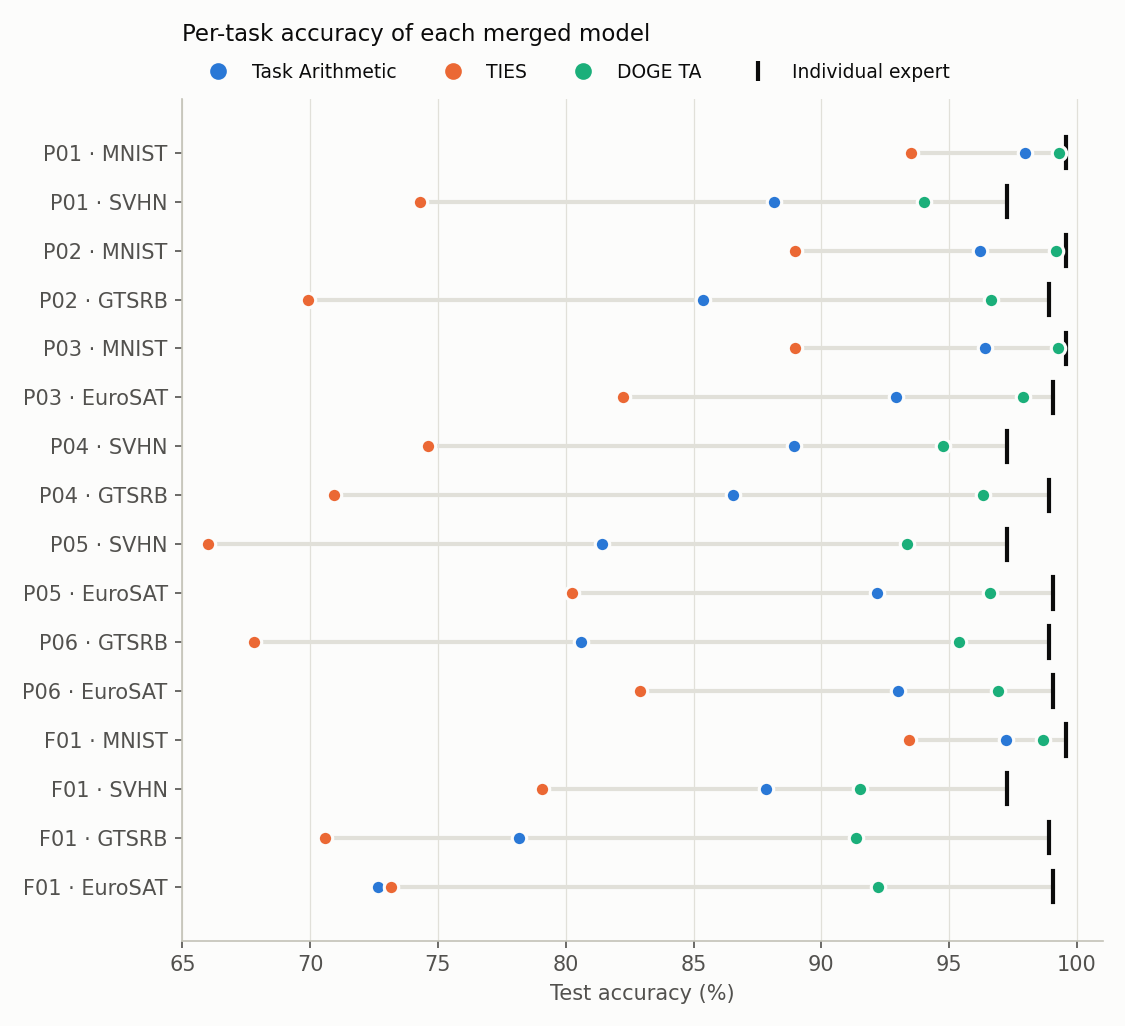

In [5]:
analyze.fig_per_task(merges, refs, FIG / "per_task_accuracy.png")
display(Image(FIG / "per_task_accuracy.png", width=760))

In [6]:
gains = main.xs("DOGE TA", level="method")[["doge_minus_ta", "doge_minus_ties"]]
display(Markdown(f"DOGE TA is best in every merge: **{gains['doge_minus_ta'].min():.2f} to {gains['doge_minus_ta'].max():.2f}** "
                 f"points over Task Arithmetic and **{gains['doge_minus_ties'].min():.2f} to {gains['doge_minus_ties'].max():.2f}** over TIES."))
gains

DOGE TA is best in every merge: **3.60 to 9.47** points over Task Arithmetic and **12.76 to 22.77** over TIES.

,doge_minus_ta,doge_minus_ties
experiment,,
P01,3.60,12.76
P02,7.12,18.47
P03,3.89,12.95
P04,7.81,22.77
P05,8.17,21.84
P06,9.37,20.82
F01,9.47,14.38


### 3.2 RQ2: merging two versus four models

For each task: retention in the four-task merge F01 versus the mean retention over the pairwise
merges that contain it (three pairs per task). Negative change = worse with four models.

In [7]:
tvf = A.two_vs_four(merges)
rows = [{"method": A.METHOD_LABELS[m], "task": L[t], **v} for m in A.METHODS for t, v in tvf["per_task"][m].items()]
rows += [{"method": A.METHOD_LABELS[m], "task": "mean", "pair_mean_retention": v["pair_mean_retention"],
          "four_task_retention": v["four_task_mean_retention"], "change": v["change"]} for m, v in tvf["overall"].items()]
pd.DataFrame(rows).pivot(index="task", columns="method", values="change").loc[[*L.values(), "mean"]]

method,DOGE TA,TIES,Task Arithmetic
task,,,
MNIST,-0.55,2.95,0.35
SVHN,-2.61,7.65,1.73
GTSRB,-4.82,1.05,-6.07
EuroSAT,-4.96,-8.74,-20.22
mean,-3.24,0.73,-6.05


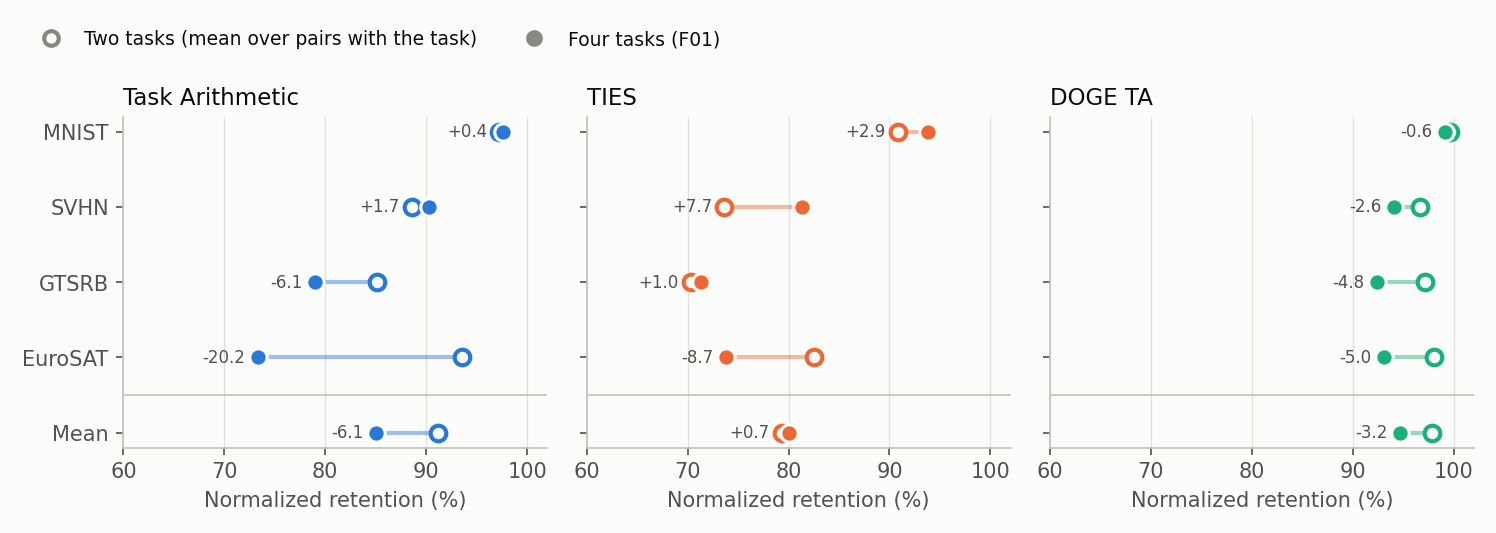

In [8]:
analyze.fig_two_vs_four(tvf, FIG / "two_vs_four.png")
display(Image(FIG / "two_vs_four.png", width=900))

### 3.3 RQ3: task-vector similarity versus retention

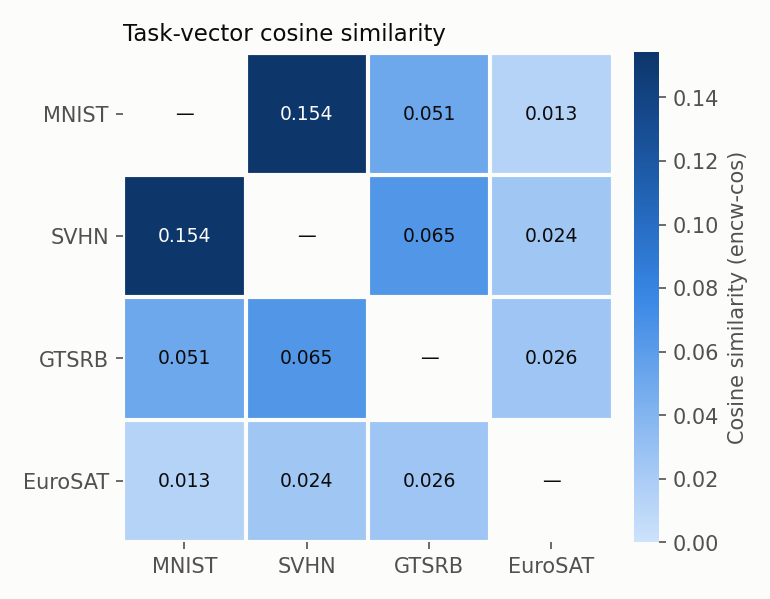

,cosine (encw-cos)
mnist-svhn,0.15
svhn-gtsrb,0.06
mnist-gtsrb,0.05
gtsrb-eurosat,0.03
svhn-eurosat,0.02
mnist-eurosat,0.01


In [9]:
sim = pd.Series(cosine, name="cosine (encw-cos)")
analyze.fig_similarity_matrix(cosine, FIG / "similarity_matrix.png")
display(Image(FIG / "similarity_matrix.png", width=420))
sim.sort_values(ascending=False).to_frame()

,method,DOGE TA,TIES,Task Arithmetic
pair,cosine,,,
P01 mnist-svhn,0.15,98.19,85.15,94.51
P04 svhn-gtsrb,0.06,97.40,74.21,89.46
P02 mnist-gtsrb,0.05,98.65,80.01,91.46
P06 gtsrb-eurosat,0.03,97.14,76.11,87.67
P05 svhn-eurosat,0.02,96.74,74.44,88.38
P03 mnist-eurosat,0.01,99.23,86.18,95.31


Spearman's ρ (descriptive, n = 6): Task Arithmetic +0.03, TIES -0.20, DOGE TA -0.03

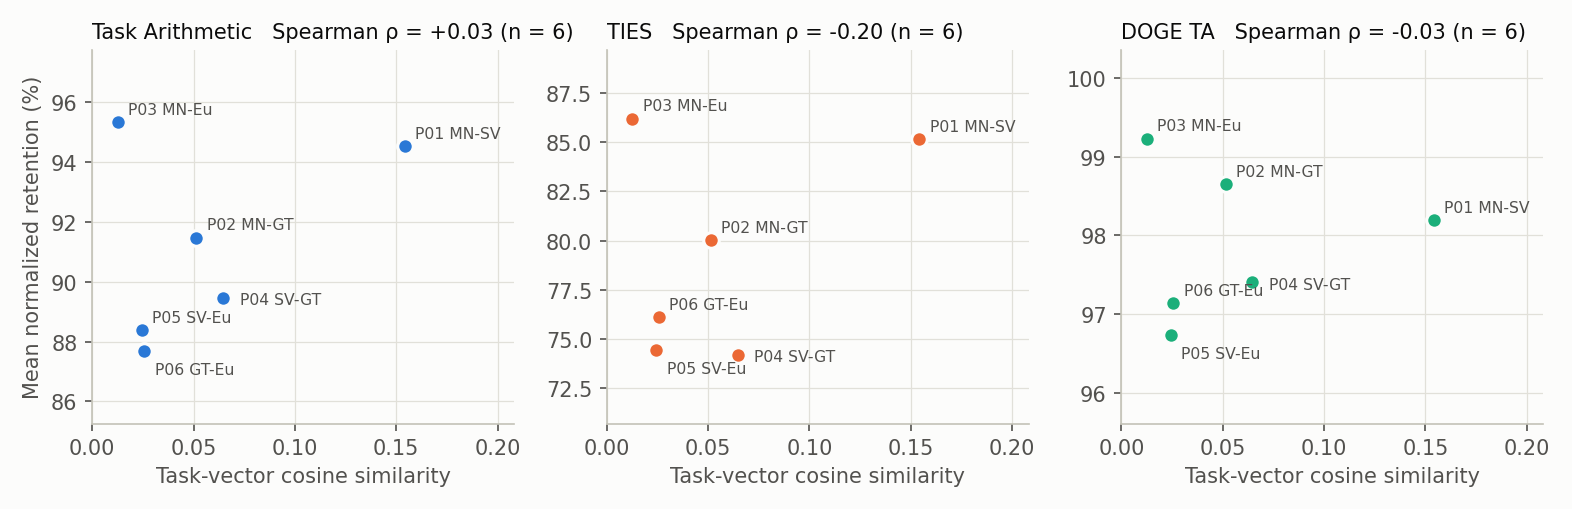

In [10]:
svr = A.similarity_vs_retention(merges, cosine)
table = pd.DataFrame([{"pair": p["experiment"] + " " + p["pair"], "cosine": p["cosine"], "method": A.METHOD_LABELS[m],
                       "retention": p["mean_normalized_retention"]} for m in A.METHODS for p in svr["methods"][m]["points"]])
display(table.pivot(index=["pair", "cosine"], columns="method", values="retention").sort_index(level="cosine", ascending=False))
display(Markdown("Spearman's ρ (descriptive, n = 6): " + ", ".join(
    f"{A.METHOD_LABELS[m]} {svr['methods'][m]['spearman_rho']:+.2f}" for m in A.METHODS)))
analyze.fig_similarity_vs_retention(svr, FIG / "similarity_vs_retention.png")
display(Image(FIG / "similarity_vs_retention.png", width=900))

### 3.4 Cost: runtime and memory (one RTX 4090; TA and TIES merge on CPU)

In [11]:
pd.DataFrame([{"experiment": e, "method": A.METHOD_LABELS[m], "merge_s": merges[e][m]["merge_time_seconds"],
               "eval_s": merges[e][m]["evaluation_time_seconds"], "peak_gpu_mb": merges[e][m]["peak_memory_mb"],
               "peak_cpu_rss_mb": merges[e][m]["peak_cpu_rss_mb"]}
              for e in analyze.experiment_order(merges) for m in A.METHODS]).set_index(["experiment", "method"])

merge_s  eval_s  peak_gpu_mb  peak_cpu_rss_mb
experiment method                                                        
P01        Task Arithmetic     5.52   16.35         0.00          2371.34
           TIES               10.67   16.41         0.00          6810.20
           DOGE TA            49.66   16.76      1752.33          4878.77
P02        Task Arithmetic     5.94   11.55         0.00          2366.21
           TIES                9.38   11.74         0.00          6839.59
           DOGE TA            47.67   12.14      1752.33          4877.20
P03        Task Arithmetic     4.64    7.96         0.00          2386.62
           TIES                8.98    8.01         0.00          7076.45
           DOGE TA            46.72    8.31      1752.33          4874.43
P04        Task Arithmetic     4.84   17.85         0.00          2386.27
           TIES                9.07   17.45         0.00          7085.30
           DOGE TA            45.30   17.78      1752.33          4884.31
P05        Task Arithmetic     4.45   13.82         0.00          2388.53
           TIES                9.50   13.43         0.00          6828.66
           DOGE TA            49.04   14.08      1752.33          4890.48
P06        Task Arithmetic     4.34    9.50         0.00          2390.99
           TIES                9.34    8.97         0.00          6836.29
           DOGE TA            46.26    9.35      1752.33          4890.45
F01        Task Arithmetic     7.58   24.38         0.00          2426.45
           TIES               12.07   24.41         0.00         12394.14
           DOGE TA            72.21   25.98      1824.33          6958.02

### 3.5 Hypotheses

Definitions: [experimental protocol section 5.5](../docs/EXPERIMENT_PROTOCOL.md#55-primary-hypotheses).

In [12]:
hyp = A.hypotheses(merges, tvf, svr)
pd.DataFrame([{"hypothesis": k, "statement": v["statement"], "verdict": v["verdict"]} for k, v in hyp.items()]).set_index("hypothesis")

,statement,verdict
hypothesis,,
H1,DOGE has higher mean accuracy than TA and TIES...,supported
H2,DOGE has higher worst-task accuracy than the b...,supported
H3,Every method retains less when merging four mo...,partly supported
H4,DOGE's retention drop from two to four models ...,partly supported
H5,Pairs with higher task-vector cosine similarit...,not supported: no consistent rank relationship...
H6,DOGE loses less performance than the baselines...,supported


## 4. Validity checks on every merge record

The checks cover the required result fields, finite merged weights, **no data access while
merging**, a passing save/reload check, test data loaded only after merging, and (DOGE) a finite
objective with the gradient projection within tolerance.

The provenance verifier separately checks recorded source/configuration hashes and the
specific documented text revisions. Its command is included in section 6.

In [13]:
status = {f"{e} {A.METHOD_LABELS[m]}": "; ".join(check_results.check(merges[e][m])) or "OK"
          for e in analyze.experiment_order(merges) for m in A.METHODS}
assert all(v == "OK" for v in status.values()), status
pd.Series(status, name="check").to_frame()

,check
P01 Task Arithmetic,OK
P01 TIES,OK
P01 DOGE TA,OK
P02 Task Arithmetic,OK
P02 TIES,OK
P02 DOGE TA,OK
P03 Task Arithmetic,OK
P03 TIES,OK
P03 DOGE TA,OK
P04 Task Arithmetic,OK


## 5. Limitations and reflections

### Interpretation of the results

* **RQ1:** Among the three methods evaluated, DOGE TA has the highest mean and worst-task
  accuracy in every task set. This conclusion applies to these experts and fixed settings.
* **RQ2:** Task Arithmetic loses most from two to four models, especially on EuroSAT; DOGE's
  average retention drop is about half as large. TIES gains slightly. A possible explanation is
  that its fixed coefficient is too small for pairs, but no coefficient sweep tests that claim.
* **RQ3:** Cosine similarity does not consistently order pairs by retention. Pairs containing
  MNIST retain best, suggesting that task identity matters in this sample. Six pairs support
  description, not a general causal or statistical conclusion.

### Limitations

1. **Fixed baseline coefficients:** $\lambda=0.3$ for Task Arithmetic and TIES is taken from an
   eight-task benchmark rather than tuned on validation data for each task set. This likely
   understates TIES; the comparison is between these fixed configurations.
2. **Limited scope:** Four tasks and one four-task merge do not establish behavior on larger
   task collections. The six pairwise similarity observations are not independent because
   tasks recur across pairs.
3. **Reproducibility evidence:** One seed is used. Task Arithmetic's repeated merge and separate
   MPS reproduction gave identical weights. DOGE starts at zero without sampling, but GPU
   numerical differences remain possible; no multi-seed or multi-hardware variance is measured.
4. **Expert provenance:** The experts are FusionBench ports, not the original Task Arithmetic
   checkpoints used by the paper. Their own-task reference accuracies are within 0.63 points of
   the paper-reported values.
5. **Implementation fidelity:** The official code uses rank/6 shared subspaces, a row-wise
   objective and only the linear encoder matrices. Adam lets 25–44% of the correction norm lie
   in the shared subspace even though gradients are projected. The float32 projection check
   uses tolerance $10^{-3}$ rather than $10^{-5}$; the numerical rationale is in the
   [paper-to-code map](../docs/PAPER_TO_CODE_MAP.md).
6. **Cost comparison:** DOGE takes 45–72 s and roughly 1.8 GB GPU memory per merge, whereas the
   baselines take 4–12 s on CPU. These are single-machine timings, include loading inside
   `method.run` and probe overhead, and do not isolate algorithmic efficiency across hardware.

### Reflections

The experiment shows why matching a paper requires checking the implementation as well as its
formulas: parameter scope, masking and the optimizer can change what is actually evaluated.
Expert-relative retention and worst-task accuracy reveal losses hidden by a single overall
mean. The strongest supported finding is DOGE's advantage under the tested configurations;
separating that advantage from coefficient choice or task selection would require additional
controlled comparisons. The shared record format and checks make the evidence inspectable
without relying on the original cloud machine.

Detailed analysis is in [ANALYSIS_NOTES.md](../docs/ANALYSIS_NOTES.md).

## 6. Reproducibility instructions — Runpod

### Dependencies and environment

The included notebook can be read with its saved outputs. Recomputing its analysis uses only
the submitted raw records and does not require a GPU or downloaded checkpoints. Repeating the
original measurements requires a CUDA GPU; the recorded runs used a Runpod RTX 4090 (24 GB).

On a fresh Runpod Linux machine with an NVIDIA driver, confirm that `git` and
[`uv`](https://docs.astral.sh/uv/getting-started/installation/) are available. Clone the repository
and use its project environment rather than the container's system Python. If using the
submission archive instead, extract it and enter the folder containing `pyproject.toml`,
then start at `nvidia-smi` below:

```bash
git clone https://github.com/rishiraj09/data-free-multi-task-model-merging-with-doge.git
cd data-free-multi-task-model-merging-with-doge
nvidia-smi
bash scripts/setup_env.sh
source .venv/bin/activate
uv pip install --python .venv/bin/python -r requirements-notebook.txt
python -m ipykernel install --user --name doge-exam --display-name "Python 3.10 (DOGE)"
```

The setup script installs Python 3.10, the exact official DOGE commit, this project in editable
mode, and the Linux pins in [`requirements.txt`](../requirements.txt). On macOS it uses
[`requirements.lock`](../requirements.lock). Notebook tools are pinned separately in
[`requirements-notebook.txt`](../requirements-notebook.txt): nbformat 5.10.4, nbclient 0.10.2 and
ipykernel 6.29.5. For interactive use, select **Python 3.10 (DOGE)** in Jupyter, restart the kernel
and run all cells in order. Downloaded checkpoints/datasets need roughly 8 GB of additional disk.
The local `tests/` directory is excluded from GitHub. If it is available, `python -m pytest -q`
runs the optional local test suite; the published result and provenance checks below remain available.

### Reanalyse the submitted results

Run these terminal commands from the project root, with the environment active:

```bash
unset DOGE_RESULTS_ROOT DOGE_FIGURES_ROOT
python scripts/verify_provenance.py
python scripts/check_results.py
python scripts/analyze.py
python scripts/build_notebook.py
```

The last command rebuilds and executes this notebook, replacing its saved outputs. The analysis
script writes timestamped tables under `results/processed/` and figures under `figures/`.
The provenance verifier checks original hashes and the specific text-only revisions recorded
in [`source_text_revisions.json`](../results/manifests/source_text_revisions.json).

### Repeat all measurements in an isolated results folder

Reference evaluations must run before merges because normalized retention uses the individual
expert accuracies from the same results root. The commands below download the pinned inputs and
repeat all seven task sets for all three methods:

```bash
export DOGE_DEVICE=cuda
export DOGE_RESULTS_ROOT="$PWD/rerun/results"
export DOGE_FIGURES_ROOT="$PWD/rerun/figures"
python scripts/verify_inventory.py
python scripts/run_experiment.py references
for e in P01 P02 P03 P04 P05 P06 F01; do
  for m in task-arithmetic ties doge-ta; do
    python scripts/run_experiment.py merge "$e" "$m"
  done
done
python scripts/compute_similarity.py
python scripts/check_results.py
python scripts/analyze.py
python scripts/compare_results.py rerun/results
```

The seed, revisions, dataset fingerprints and method settings are supplied by the included
configs. Floating-point differences across CUDA devices or libraries can affect DOGE; the
comparison reports accuracy differences and merged-weight identity. To return to the submitted
results, run `unset DOGE_DEVICE DOGE_RESULTS_ROOT DOGE_FIGURES_ROOT`.

The original pod had no persistent volume. Keep an independent copy of `rerun/results/` and
`rerun/figures/` before stopping a replacement pod. Full setup, result-format and troubleshooting
instructions are in [INSTRUCTION.md](../INSTRUCTION.md).

## 7. References

### Papers

1. Wei, Y., Tang, A., Shen, L., Hu, Z., Yuan, C., and Cao, X. (2025).
   [*Modeling Multi-Task Model Merging as Adaptive Projective Gradient Descent*](https://proceedings.mlr.press/v267/wei25k.html).
   ICML, PMLR 267. Main method and experimental starting point.
2. Ilharco, G., et al. (2023).
   [*Editing Models with Task Arithmetic*](https://arxiv.org/abs/2212.04089). ICLR.
3. Yadav, P., Tam, D., Choshen, L., Raffel, C., and Bansal, M. (2023).
   [*TIES-Merging: Resolving Interference When Merging Models*](https://papers.neurips.cc/paper_files/paper/2023/hash/1644c9af28ab7916874f6fd6228a9bcf-Abstract-Conference.html).
   NeurIPS 36.
4. Radford, A., et al. (2021).
   [*Learning Transferable Visual Models From Natural Language Supervision*](https://proceedings.mlr.press/v139/radford21a.html).
   ICML, PMLR 139. CLIP architecture and zero-shot evaluation.

### Code and checkpoints

- [Official DOGE repository at the exact experimental commit](https://github.com/WalkerWorldPeace/DOGE/tree/ca0a0a10c45bc0965f52f0815d6a6581ee103f85).
  This FusionBench 0.2.11 fork supplies all three merging implementations.
- [FusionBench project](https://github.com/tanganke/fusion_bench), maintained by Anke Tang and contributors;
  the experiments use the pinned DOGE fork above, not the current upstream release.
- [Pretrained CLIP ViT-B/32](https://huggingface.co/openai/clip-vit-base-patch32) and FusionBench experts for
  [MNIST](https://huggingface.co/tanganke/clip-vit-base-patch32_mnist),
  [SVHN](https://huggingface.co/tanganke/clip-vit-base-patch32_svhn),
  [GTSRB](https://huggingface.co/tanganke/clip-vit-base-patch32_gtsrb), and
  [EuroSAT](https://huggingface.co/tanganke/clip-vit-base-patch32_eurosat).

### Datasets and local evidence

- Dataset sources: [MNIST](https://huggingface.co/datasets/ylecun/mnist),
  [SVHN](https://huggingface.co/datasets/ufldl-stanford/svhn),
  [GTSRB](https://huggingface.co/datasets/tanganke/gtsrb), and
  [EuroSAT](https://huggingface.co/datasets/tanganke/eurosat). The exact revisions, test sizes and
  fingerprints used here are in [`configs/pins.yaml`](../configs/pins.yaml) and the
  [checkpoint/dataset inventory](../results/manifests/inventory__20261018T213330Z.json).
- [Raw measured records](../results/raw/), [submitted analysis tables](../results/processed/analysis__20261018T222449Z/),
  [figures](../figures/analysis__20261018T222449Z/), and
  [paper-to-code comparison](../docs/PAPER_TO_CODE_MAP.md).